# Datensatz runterladen, einlesen, grob verstehen

In [2]:
pip install kagglehub

  Using cached kagglehub-1.0.2-py3-none-any.whl.metadata (40 kB)
  Using cached kagglesdk-0.1.37-py3-none-any.whl.metadata (13 kB)
  Using cached tqdm-4.70.1-py3-none-any.whl.metadata (57 kB)
  Using cached protobuf-7.36.2-cp310-abi3-manylinux2014_x86_64.whl.metadata (595 bytes)
Using cached kagglehub-1.0.2-py3-none-any.whl (70 kB)
Using cached kagglesdk-0.1.37-py3-none-any.whl (262 kB)
Using cached protobuf-7.36.2-cp310-abi3-manylinux2014_x86_64.whl (343 kB)
Using cached tqdm-4.70.1-py3-none-any.whl (80 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [kagglehub]━ 2/4 [kagglesdk]
Note: you may need to restart the kernel to use updated packages.


In [1]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("hmavrodiev/london-bike-sharing-dataset")

print("Path to dataset files:", path)

/home/juebrauer/miniconda3/envs/env_aki/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Path to dataset files: /home/juebrauer/.cache/kagglehub/datasets/hmavrodiev/london-bike-sharing-dataset/versions/1


In [2]:
path

'/home/juebrauer/.cache/kagglehub/datasets/hmavrodiev/london-bike-sharing-dataset/versions/1'

In [3]:
ls $path

london_merged.csv


In [4]:
import os
os.listdir(path)

['london_merged.csv']

In [6]:
import pandas
filename = path + "/london_merged.csv"
df = pandas.read_csv(filename)

In [7]:
df

,timestamp,cnt,t1,t2,hum,wind_speed,weather_code,is_holiday,is_weekend,season
0,2015-01-04 00:00:00,182,3.0,2.0,93.0,6.0,3.0,0.0,1.0,3.0
1,2015-01-04 01:00:00,138,3.0,2.5,93.0,5.0,1.0,0.0,1.0,3.0
2,2015-01-04 02:00:00,134,2.5,2.5,96.5,0.0,1.0,0.0,1.0,3.0
3,2015-01-04 03:00:00,72,2.0,2.0,100.0,0.0,1.0,0.0,1.0,3.0
4,2015-01-04 04:00:00,47,2.0,0.0,93.0,6.5,1.0,0.0,1.0,3.0
...,...,...,...,...,...,...,...,...,...,...
17409,2017-01-03 19:00:00,1042,5.0,1.0,81.0,19.0,3.0,0.0,0.0,3.0
17410,2017-01-03 20:00:00,541,5.0,1.0,81.0,21.0,4.0,0.0,0.0,3.0
17411,2017-01-03 21:00:00,337,5.5,1.5,78.5,24.0,4.0,0.0,0.0,3.0
17412,2017-01-03 22:00:00,224,5.5,1.5,76.0,23.0,4.0,0.0,0.0,3.0


# Datumsformat anpassen, Zeitliches Slices

In [15]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 17414 entries, 0 to 17413
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   timestamp     17414 non-null  str    
 1   cnt           17414 non-null  int64  
 2   t1            17414 non-null  float64
 3   t2            17414 non-null  float64
 4   hum           17414 non-null  float64
 5   wind_speed    17414 non-null  float64
 6   weather_code  17414 non-null  float64
 7   is_holiday    17414 non-null  float64
 8   is_weekend    17414 non-null  float64
 9   season        17414 non-null  float64
dtypes: float64(8), int64(1), str(1)
memory usage: 1.3 MB


In [11]:
type( df["timestamp"] )

pandas.Series

In [12]:
type( df )

pandas.DataFrame

In [13]:
df["timestamp"]

0        2015-01-04 00:00:00
1        2015-01-04 01:00:00
2        2015-01-04 02:00:00
3        2015-01-04 03:00:00
4        2015-01-04 04:00:00
                ...         
17409    2017-01-03 19:00:00
17410    2017-01-03 20:00:00
17411    2017-01-03 21:00:00
17412    2017-01-03 22:00:00
17413    2017-01-03 23:00:00
Name: timestamp, Length: 17414, dtype: str

In [16]:
df["timestamp"] = pandas.to_datetime( df["timestamp"] )

In [46]:
import kagglehub
import pandas

path = kagglehub.dataset_download("hmavrodiev/london-bike-sharing-dataset")
filename = path + "/london_merged.csv"
df = pandas.read_csv(filename)
df["timestamp"] = pandas.to_datetime( df["timestamp"] )
df.set_index( "timestamp", inplace=True )

In [47]:
df.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 17414 entries, 2015-01-04 00:00:00 to 2017-01-03 23:00:00
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   cnt           17414 non-null  int64  
 1   t1            17414 non-null  float64
 2   t2            17414 non-null  float64
 3   hum           17414 non-null  float64
 4   wind_speed    17414 non-null  float64
 5   weather_code  17414 non-null  float64
 6   is_holiday    17414 non-null  float64
 7   is_weekend    17414 non-null  float64
 8   season        17414 non-null  float64
dtypes: float64(8), int64(1)
memory usage: 1.3 MB


In [37]:
df.head(12)

,cnt,t1,t2,hum,wind_speed,weather_code,is_holiday,is_weekend,season
timestamp,,,,,,,,,
2015-01-04 00:00:00,182,3.0,2.0,93.0,6.0,3.0,0.0,1.0,3.0
2015-01-04 01:00:00,138,3.0,2.5,93.0,5.0,1.0,0.0,1.0,3.0
2015-01-04 02:00:00,134,2.5,2.5,96.5,0.0,1.0,0.0,1.0,3.0
2015-01-04 03:00:00,72,2.0,2.0,100.0,0.0,1.0,0.0,1.0,3.0
2015-01-04 04:00:00,47,2.0,0.0,93.0,6.5,1.0,0.0,1.0,3.0
2015-01-04 05:00:00,46,2.0,2.0,93.0,4.0,1.0,0.0,1.0,3.0
2015-01-04 06:00:00,51,1.0,-1.0,100.0,7.0,4.0,0.0,1.0,3.0
2015-01-04 07:00:00,75,1.0,-1.0,100.0,7.0,4.0,0.0,1.0,3.0
2015-01-04 08:00:00,131,1.5,-1.0,96.5,8.0,4.0,0.0,1.0,3.0


In [38]:
df.loc["2015-01-04"]

,cnt,t1,t2,hum,wind_speed,weather_code,is_holiday,is_weekend,season
timestamp,,,,,,,,,
2015-01-04 00:00:00,182,3.0,2.0,93.0,6.0,3.0,0.0,1.0,3.0
2015-01-04 01:00:00,138,3.0,2.5,93.0,5.0,1.0,0.0,1.0,3.0
2015-01-04 02:00:00,134,2.5,2.5,96.5,0.0,1.0,0.0,1.0,3.0
2015-01-04 03:00:00,72,2.0,2.0,100.0,0.0,1.0,0.0,1.0,3.0
2015-01-04 04:00:00,47,2.0,0.0,93.0,6.5,1.0,0.0,1.0,3.0
2015-01-04 05:00:00,46,2.0,2.0,93.0,4.0,1.0,0.0,1.0,3.0
2015-01-04 06:00:00,51,1.0,-1.0,100.0,7.0,4.0,0.0,1.0,3.0
2015-01-04 07:00:00,75,1.0,-1.0,100.0,7.0,4.0,0.0,1.0,3.0
2015-01-04 08:00:00,131,1.5,-1.0,96.5,8.0,4.0,0.0,1.0,3.0


In [39]:
df.loc["2015-01-04"].shape

(24, 9)

In [40]:
df.loc["2015"]

,cnt,t1,t2,hum,wind_speed,weather_code,is_holiday,is_weekend,season
timestamp,,,,,,,,,
2015-01-04 00:00:00,182,3.0,2.0,93.0,6.0,3.0,0.0,1.0,3.0
2015-01-04 01:00:00,138,3.0,2.5,93.0,5.0,1.0,0.0,1.0,3.0
2015-01-04 02:00:00,134,2.5,2.5,96.5,0.0,1.0,0.0,1.0,3.0
2015-01-04 03:00:00,72,2.0,2.0,100.0,0.0,1.0,0.0,1.0,3.0
2015-01-04 04:00:00,47,2.0,0.0,93.0,6.5,1.0,0.0,1.0,3.0
...,...,...,...,...,...,...,...,...,...
2015-12-31 19:00:00,359,9.0,6.0,76.0,21.0,2.0,0.0,0.0,3.0
2015-12-31 20:00:00,304,8.0,5.0,82.0,18.0,1.0,0.0,0.0,3.0
2015-12-31 21:00:00,369,8.0,5.0,73.5,19.5,1.0,0.0,0.0,3.0


In [43]:
df.loc["2015-03" : "2015-05"]["cnt"].mean()

np.float64(1100.3310626702996)

In [44]:
df.loc["2015-06" : "2015-08"]["cnt"].mean()

np.float64(1448.382553384825)

# Zeitreihen visualisieren

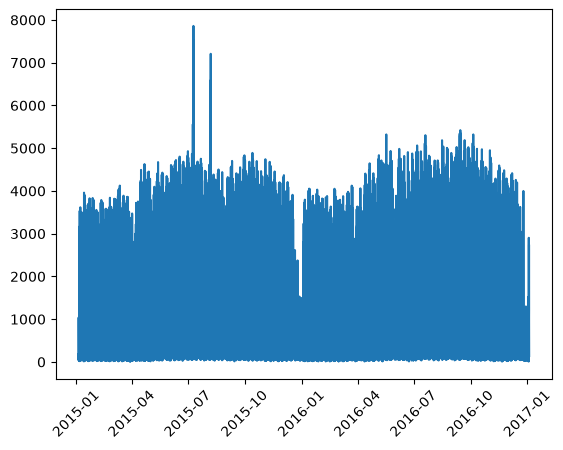

In [53]:
import matplotlib.pyplot as plt
plt.plot(df["cnt"])
plt.xticks(rotation=45)
plt.show()

In [54]:
df.query("cnt > 6000")

,cnt,t1,t2,hum,wind_speed,weather_code,is_holiday,is_weekend,season
timestamp,,,,,,,,,
2015-07-09 08:00:00,7531,14.5,14.5,61.0,19.0,2.0,0.0,0.0,1.0
2015-07-09 16:00:00,6033,23.0,22.0,26.0,11.0,1.0,0.0,0.0,1.0
2015-07-09 17:00:00,7860,23.0,22.0,27.0,11.0,1.0,0.0,0.0,1.0
2015-07-09 18:00:00,6913,22.5,21.5,29.0,13.0,1.0,0.0,0.0,1.0
2015-08-06 08:00:00,6585,19.0,19.0,78.0,12.0,7.0,0.0,0.0,1.0
2015-08-06 17:00:00,7208,22.5,22.5,55.0,17.5,2.0,0.0,0.0,1.0
2015-08-06 18:00:00,6394,21.5,21.5,58.5,20.0,2.0,0.0,0.0,1.0


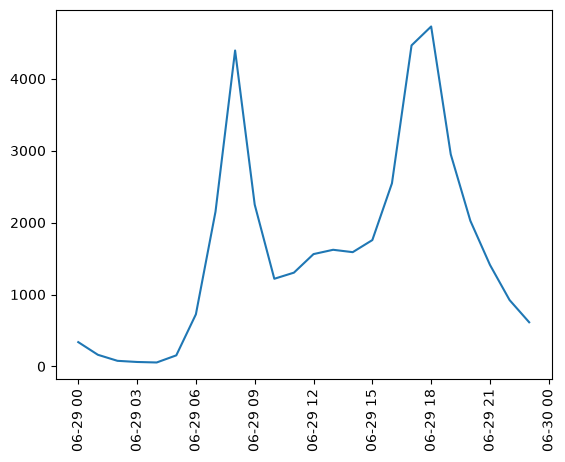

In [61]:
plt.plot( df.loc["2015-06-29" : "2015-06-]["cnt"] )
plt.xticks(rotation = 90)
plt.show()

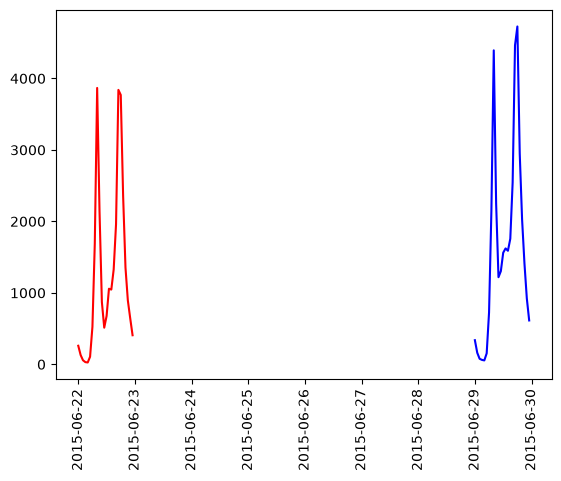

In [64]:
plt.plot( df.loc["2015-06-29"]["cnt"], color="blue" )
plt.plot( df.loc["2015-06-22"]["cnt"], color="red" )
plt.xticks(rotation = 90)
plt.show()

# Mehrere Montage übereinander plotten

In [67]:
s = df.loc["2015-06-29"]["cnt"]
s

timestamp
2015-06-29 00:00:00     338
2015-06-29 01:00:00     162
2015-06-29 02:00:00      78
2015-06-29 03:00:00      62
2015-06-29 04:00:00      55
2015-06-29 05:00:00     154
2015-06-29 06:00:00     725
2015-06-29 07:00:00    2152
2015-06-29 08:00:00    4393
2015-06-29 09:00:00    2250
2015-06-29 10:00:00    1219
2015-06-29 11:00:00    1304
2015-06-29 12:00:00    1562
2015-06-29 13:00:00    1622
2015-06-29 14:00:00    1589
2015-06-29 15:00:00    1757
2015-06-29 16:00:00    2546
2015-06-29 17:00:00    4464
2015-06-29 18:00:00    4727
2015-06-29 19:00:00    2949
2015-06-29 20:00:00    2025
2015-06-29 21:00:00    1412
2015-06-29 22:00:00     923
2015-06-29 23:00:00     614
Name: cnt, dtype: int64

In [68]:
s.index

DatetimeIndex(['2015-06-29 00:00:00', '2015-06-29 01:00:00',
               '2015-06-29 02:00:00', '2015-06-29 03:00:00',
               '2015-06-29 04:00:00', '2015-06-29 05:00:00',
               '2015-06-29 06:00:00', '2015-06-29 07:00:00',
               '2015-06-29 08:00:00', '2015-06-29 09:00:00',
               '2015-06-29 10:00:00', '2015-06-29 11:00:00',
               '2015-06-29 12:00:00', '2015-06-29 13:00:00',
               '2015-06-29 14:00:00', '2015-06-29 15:00:00',
               '2015-06-29 16:00:00', '2015-06-29 17:00:00',
               '2015-06-29 18:00:00', '2015-06-29 19:00:00',
               '2015-06-29 20:00:00', '2015-06-29 21:00:00',
               '2015-06-29 22:00:00', '2015-06-29 23:00:00'],
              dtype='datetime64[us]', name='timestamp', freq=None)

In [69]:
s.values

array([ 338,  162,   78,   62,   55,  154,  725, 2152, 4393, 2250, 1219,
       1304, 1562, 1622, 1589, 1757, 2546, 4464, 4727, 2949, 2025, 1412,
        923,  614])

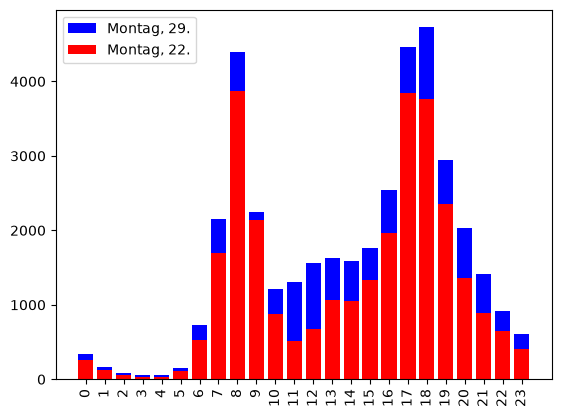

In [78]:
s1 = df.loc["2015-06-29"]["cnt"]
s2 = df.loc["2015-06-22"]["cnt"]
plt.bar(range(0,24), s1.values, color="blue", label="Montag, 29.")
plt.bar(range(0,24), s2.values, color="red",  label="Montag, 22.")
plt.xticks( range(0,24), rotation=90 )
plt.legend()
plt.show()

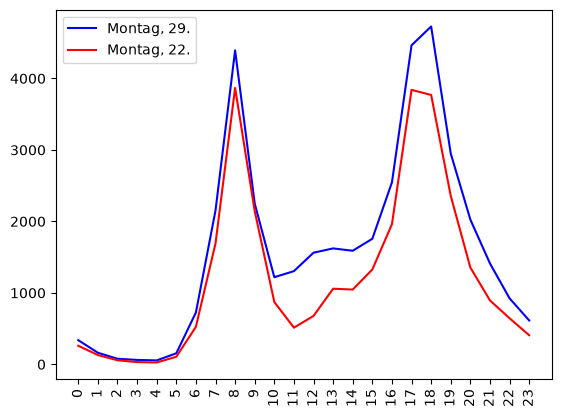

In [79]:
s1 = df.loc["2015-06-29"]["cnt"]
s2 = df.loc["2015-06-22"]["cnt"]
plt.plot(s1.values, color="blue", label="Montag, 29.")
plt.plot(s2.values, color="red",  label="Montag, 22.")
plt.xticks( range(0,24), rotation=90 )
plt.legend()
plt.show()

In [82]:
tag = 15
print( f"2015-06-{tag}" )

2015-06-15


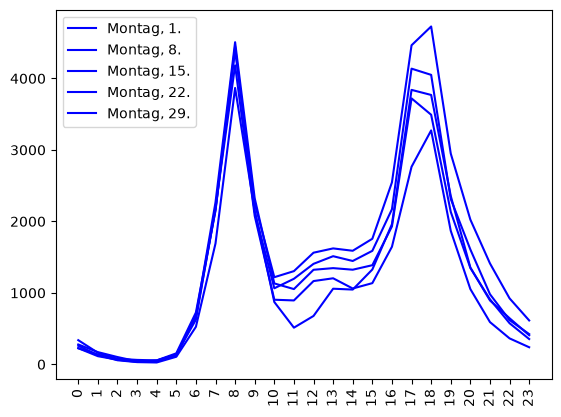

In [84]:
for tag in [1,8,15,22,29]:
    s = df.loc[f"2015-06-{tag}"]["cnt"]
    plt.plot(s.values, color="blue", label=f"Montag, {tag}.")
    plt.xticks( range(0,24), rotation=90 )
    plt.legend()

plt.show()

# Zeitliches Muster pro Stunde für Montage bearbeiten

In [85]:
df

,cnt,t1,t2,hum,wind_speed,weather_code,is_holiday,is_weekend,season
timestamp,,,,,,,,,
2015-01-04 00:00:00,182,3.0,2.0,93.0,6.0,3.0,0.0,1.0,3.0
2015-01-04 01:00:00,138,3.0,2.5,93.0,5.0,1.0,0.0,1.0,3.0
2015-01-04 02:00:00,134,2.5,2.5,96.5,0.0,1.0,0.0,1.0,3.0
2015-01-04 03:00:00,72,2.0,2.0,100.0,0.0,1.0,0.0,1.0,3.0
2015-01-04 04:00:00,47,2.0,0.0,93.0,6.5,1.0,0.0,1.0,3.0
...,...,...,...,...,...,...,...,...,...
2017-01-03 19:00:00,1042,5.0,1.0,81.0,19.0,3.0,0.0,0.0,3.0
2017-01-03 20:00:00,541,5.0,1.0,81.0,21.0,4.0,0.0,0.0,3.0
2017-01-03 21:00:00,337,5.5,1.5,78.5,24.0,4.0,0.0,0.0,3.0


In [93]:
import kagglehub
import pandas

path = kagglehub.dataset_download("hmavrodiev/london-bike-sharing-dataset")
filename = path + "/london_merged.csv"
df = pandas.read_csv(filename)
df["timestamp"] = pandas.to_datetime( df["timestamp"] )
df.set_index( "timestamp", inplace=True )

# Zwei neue Spalten erzeugen
df["hour"] = df.index.hour
df["weekday"] = df.index.weekday # Mo:0, Di:1, ..., So:6

In [97]:
df.loc["2015"].query("weekday == 0")

,cnt,t1,t2,hum,wind_speed,weather_code,is_holiday,is_weekend,season,hour,weekday
timestamp,,,,,,,,,,,
2015-01-05 00:00:00,83,4.0,3.0,93.0,6.0,4.0,0.0,0.0,3.0,0,0
2015-01-05 01:00:00,67,4.0,3.5,93.0,5.0,4.0,0.0,0.0,3.0,1,0
2015-01-05 02:00:00,32,5.0,4.0,87.0,6.0,4.0,0.0,0.0,3.0,2,0
2015-01-05 03:00:00,22,6.0,4.5,84.0,7.5,4.0,0.0,0.0,3.0,3,0
2015-01-05 04:00:00,38,6.5,5.0,84.0,8.0,4.0,0.0,0.0,3.0,4,0
...,...,...,...,...,...,...,...,...,...,...,...
2015-12-28 19:00:00,520,12.0,12.0,67.0,24.0,1.0,1.0,0.0,3.0,19,0
2015-12-28 20:00:00,526,12.0,12.0,67.0,24.0,1.0,1.0,0.0,3.0,20,0
2015-12-28 21:00:00,453,13.0,13.0,63.0,21.0,1.0,1.0,0.0,3.0,21,0


In [106]:
pt = pandas.pivot_table(df.loc["2015"], columns="hour", aggfunc="mean").transpose()["cnt"]
pt

hour
0      299.205556
1      202.936111
2      141.806723
3       98.229692
4       73.596639
5      108.492997
6      456.060942
7     1435.650970
8     2841.651934
9     1627.867403
10    1048.708333
11    1130.654696
12    1407.328729
13    1470.041551
14    1445.360111
15    1540.939058
16    1851.262431
17    2779.670360
18    2583.789474
19    1626.588889
20    1046.813889
21     732.905556
22     582.532033
23     444.601671
Name: cnt, dtype: float64

# Eine erste Prädiktion!

In [109]:
import kagglehub
import pandas

path = kagglehub.dataset_download("hmavrodiev/london-bike-sharing-dataset")
filename = path + "/london_merged.csv"
df = pandas.read_csv(filename)
df["timestamp"] = pandas.to_datetime( df["timestamp"] )
df.set_index( "timestamp", inplace=True )

# Zwei neue Spalten erzeugen
df["hour"] = df.index.hour
df["weekday"] = df.index.weekday # Mo:0, Di:1, ..., So:6

muster = pandas.pivot_table(df.loc["2015"].query("weekday==0"),
                            columns="hour", aggfunc="mean").transpose()["cnt"]
muster

hour
0      217.538462
1      118.923077
2       75.461538
3       49.384615
4       50.019231
5      107.538462
6      521.450980
7     1716.019231
8     3482.384615
9     1769.480769
10     889.538462
11     899.653846
12    1133.673077
13    1197.333333
14    1136.352941
15    1232.647059
16    1639.557692
17    3060.423077
18    2907.980769
19    1720.480769
20    1047.274510
21     676.384615
22     467.326923
23     304.634615
Name: cnt, dtype: float64

In [118]:
3482-3674

-192

In [113]:
gt = df.loc["2016-03-14"]["cnt"]
gt

timestamp
2016-03-14 00:00:00     120
2016-03-14 01:00:00      68
2016-03-14 02:00:00      31
2016-03-14 03:00:00      21
2016-03-14 04:00:00      35
2016-03-14 05:00:00     100
2016-03-14 06:00:00     539
2016-03-14 07:00:00    1912
2016-03-14 08:00:00    3674
2016-03-14 09:00:00    1814
2016-03-14 10:00:00     884
2016-03-14 11:00:00     816
2016-03-14 12:00:00    1043
2016-03-14 13:00:00    1023
2016-03-14 14:00:00    1056
2016-03-14 15:00:00    1255
2016-03-14 16:00:00    1650
2016-03-14 17:00:00    3163
2016-03-14 18:00:00    2801
2016-03-14 19:00:00    1446
2016-03-14 20:00:00     814
2016-03-14 21:00:00     548
2016-03-14 22:00:00     409
2016-03-14 23:00:00     226
Name: cnt, dtype: int64

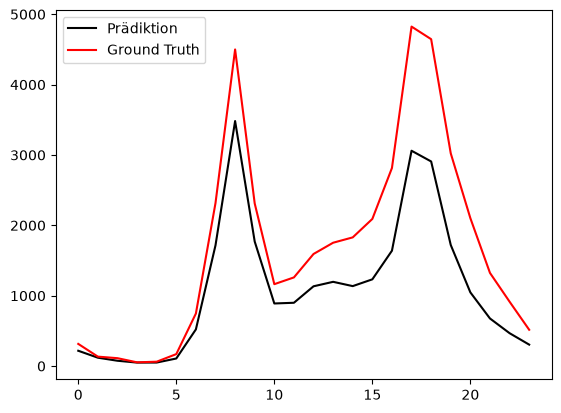

In [119]:
gt = df.loc["2016-07-25"]["cnt"]

plt.plot(muster.values, color="black", label="Prädiktion")
plt.plot(gt.values, color="red", label="Ground Truth")
plt.legend()
plt.show()